# Frequency probing: KernelSynth and Light TSMixup backgrounds

## tl;dr

This notebook repeats the pure-tone probing protocol with a known added tone
on generated backgrounds, at the same ten stages. Each of 100 backgrounds per
family creates its own labelled sweep and therefore its own SV for every
checkpoint, stage and task; the export summarises them by median and
interquartile range. Each background also carries the lock/control pair it has
in the recovery count of Appendix G, so the located rates at candidate sites
and beside them can be compared stage by stage with what the forecast returns.
Results are computed below before they are summarised.

## Context & Methods

Frozen Chronos-Bolt-Tiny checkpoints are read at ten probe points: the [REG]
vector after each of the four encoder blocks (its last position) and after each
of the four decoder blocks (the single query token), the input of the output
projection, and its output, the quantile head. The seven hierarchical binary
frequency tasks are ordered by decision threshold: LL, L, LH, Mid, HL, H and HH.
We retain their existing bands and boundaries.

**Description length by stage.** For each task, unique frequencies are assigned
to five class-stratified prequential blocks. All phases at a frequency remain in
the same block. The first block is charged uniformly at one bit per label; every
later block is encoded by a linear probe trained only on preceding blocks. The
scaler and PCA (up to 20 components) are fitted inside that preceding-data fit,
followed by logistic regression. A fixed seed of 42 governs splits, probe
randomness and both controls. The reported space saving is
\[
SV = 1 - \frac{L_{\mathrm{MDL}}}{n}.
\]
Positive SV means label compression, zero means no saving, and negative values
are retained. The initial uniform block sets a design-dependent upper bound
near 0.8. SV measures the readability of frequency labels from these
representations; it does not measure compression of waveform samples.

**Two controls.** *Shuffled labels*: the same blocks and probe on permuted
labels. *Untrained network*: the same architecture with randomly initialised
weights reads the same contexts and is scored in the same way. What the
untrained network already exposes comes from the tokenisation and the
architecture; only the gap between the two networks can be attributed to training.

**Lock/control reading.** This mirrors the recovery count of the frequency
analysis, read inside the network instead of on the forecast. A tone on a
candidate site (lock) and a tone beside it (control, more than 2 Hz from every
candidate of the geometry) are presented at every phase. A tone is *located* at
a stage when the three band probes on its path (Mid, then L or H, then one of
LL, LH, HL, HH) all return its label, which places it in an eighth of the band.
The probes are fitted on the sweep without the frequencies within 1 Hz of the
lock or control tones, so no located tone was seen in fitting. The outcome is
the located rate at lock and control and their difference, stage by stage. Task
boundaries lie beside several candidate sites, so the reading is repeated on the
pairs whose tones all lie at least 4 Hz from the boundaries on their path.

### Key assumptions

- Signals are sampled at 512 Hz. The full grid is 2–250 Hz in 1-Hz steps,
  with ten explicitly distinct phases per frequency. Candidate sites keep
  their exact, possibly non-integer, value in the lock/control reading.
- Context length is the largest \(L\le512\) satisfying \(L\bmod P=0\) and
  \((L-P)\bmod S=0\), avoiding masked patch padding and uncovered samples.
- The published checkpoint and the fifteen retrained geometries use their
  existing, identified weights; no model is retrained here.
- The grouped five-block estimator is the repository's adapted protocol.
  The figure layout follows [Pagani et al., Figure 3](https://arxiv.org/html/2605.06361v1).
- These values are not those of `02_mdl_bandtasks.parquet` (Model B), whose
  blocks are not grouped by frequency.

### Set up the experiment

In [1]:
from pathlib import Path
import os
import sys

import pandas as pd
from IPython.display import Image, Markdown, display

REPO = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "notebooks" / "support_scripts" / "probing_lib.py").is_file()),
    None,
)
if REPO is None:
    raise RuntimeError("Open this notebook from the patchAliasing repository.")
sys.path.insert(0, str(REPO / "notebooks" / "support_scripts"))

from probing_protocol import ProbeConfig, context_length, make_design
from probing_lib import MODELS

MODE = os.environ.get("PATCHALIASING_PROBING_MODE", "full").strip().lower()
if MODE not in {"full", "smoke"}:
    raise ValueError("PATCHALIASING_PROBING_MODE must be 'full' or 'smoke'.")
# The untrained-network control doubles the cost of every background dataset.
# Set RANDOM_INIT = False to run the trained network alone; the pure-tone
# notebook always carries the control.
RANDOM_INIT = True
cfg = ProbeConfig.smoke(random_init=RANDOM_INIT) if MODE == "smoke" else ProbeConfig(random_init=RANDOM_INIT)
models = tuple(model for model in MODELS if model.tag == "retrained-p16-s16") if MODE == "smoke" else MODELS
ROOT = REPO / "notebooks" / "_run" / "probing"
DEVICE = "cpu"
TASK_ORDER = ["LL", "L", "LH", "Mid", "HL", "H", "HH"]
STAGE_ORDER = ["enc_0", "enc_1", "enc_2", "enc_3", "dec_0", "dec_1", "dec_2", "dec_3",
               "output_reg", "output_head"]
# Tracked copies of the values the report quotes (notebooks/_run is not in the repository).
PUBLISHED = REPO / "notebooks" / "signal_analysis" / "results" / "probing"

print(f"Mode: {MODE}; device: {DEVICE}; checkpoints: {len(models)}")
if MODE == "smoke":
    display(Markdown("**SMOKE CHECK — reduced design; these results are not report estimates.**"))

def lock_control_panel(summary, family, network="trained", suffix=""):
    """Geometry by stage: located rate at lock / at control, in per cent."""
    part = summary.loc[summary["family"].eq(family) & summary["network"].eq(network)].copy()
    part["cell"] = [("-" if pd.isna(l) or pd.isna(c) else f"{l:.0f}/{c:.0f}")
                    for l, c in zip(part[f"lock_pct{suffix}"], part[f"control_pct{suffix}"])]
    return part.pivot(index="model", columns="stage", values="cell").reindex(
        index=[model.tag for model in models], columns=STAGE_ORDER)


def net_panel(summary, family, network="trained", suffix=""):
    part = summary.loc[summary["family"].eq(family) & summary["network"].eq(network)]
    return part.pivot(index="model", columns="stage", values=f"net_pct{suffix}").reindex(
        index=[model.tag for model in models], columns=STAGE_ORDER).round(1)


def publish(paths):
    """Copy full-design exports next to the notebook so the report values are traceable."""
    import shutil
    if MODE != "full":
        return []
    PUBLISHED.mkdir(parents=True, exist_ok=True)
    copied = []
    for path in paths:
        shutil.copy2(path, PUBLISHED / path.name)
        copied.append(PUBLISHED / path.name)
    return copied

Mode: full; device: cpu; checkpoints: 16


## Data

The Appendix G recipes generate 100 independent backgrounds per family.
Light TSMixup uses 1–4 components, with frequencies separated by at least
10 Hz; KernelSynth uses at most five kernels. Each canonical 544-sample draw
is generated once and normalised to unit variance, then shared across all
checkpoints and cropped to their exact context lengths.

Every background receives the same frequency/phase sweep as the pure-tone
notebook. The injected sinusoid has amplitude 1.5 times the canonical
background standard deviation; the sum is not renormalised. Its known
frequency supplies the label, including when the background itself contains
nearby energy.

One background therefore contributes a *dataset* of frequency/phase
variants, rather than a single binary compression outcome for one waveform.
The full result contains 16 × 2 × 100 × 10 × 7 = 224,000 task/stage rows.

For the lock/control reading, background *i* of a geometry receives the same
candidate site and the same control side it has in the recovery count
(Appendix G), so the two analyses see the same pairs. The lock and the control
tone are each read at the ten phases, by probes fitted on the sweep of that
same background.

In [2]:
design = make_design(cfg)
coverage = pd.DataFrame([
    {"model": model.tag, "P": model.P, "S": model.S,
     "context_samples": context_length(model.P, model.S)}
    for model in models
])
display(coverage)
print(f"{design['frequency'].nunique()} frequencies × {cfg.n_phases} phases = {len(design)} contexts per sweep")
display(design.head(6))

print(f"Backgrounds per family: {cfg.n_backgrounds}; families: KernelSynth and Light TSMixup")
print(f"Expected task/stage rows: {len(models) * 2 * cfg.n_backgrounds * 10 * 7:,}")

249 frequencies × 10 phases = 2490 contexts per sweep
Backgrounds per family: 100; families: KernelSynth and Light TSMixup
Expected task/stage rows: 224,000


,model,P,S,context_samples
0,official-p16-s16,16,16,512
1,retrained-p8-s8,8,8,512
2,retrained-p16-s8,16,8,512
3,retrained-p16-s12,16,12,496
4,retrained-p16-s16,16,16,512
5,retrained-p24-s8,24,8,504
6,retrained-p24-s12,24,12,504
7,retrained-p24-s16,24,16,504
8,retrained-p24-s20,24,20,504
9,retrained-p24-s24,24,24,504


,frequency,phase,phase_index
0,2.0,0.000000,0
1,2.0,0.628319,1
2,2.0,1.256637,2
3,2.0,1.884956,3
4,2.0,2.513274,4
5,2.0,3.141593,5


## Results

### Run or resume the background sweeps

The runner saves atomic background/model shards and validates all expected
rows before exporting counts. A failed draw or fit remains an error; it is
never dropped from the denominator. Repeating the same command resumes
matching completed work. Full mode requires exactly 100 valid background
results per family, checkpoint, stage and task.

In [3]:
from probing_lib import run_complex

results, run_dir = run_complex(ROOT, cfg=cfg, models=models, device=DEVICE)
trials = pd.read_csv(run_dir / "lock_control.csv")
prefix = "smoke_" if MODE == "smoke" else ""
lock_control = pd.read_csv(run_dir / f"{prefix}complex_lock_control.csv")
print(f"Validated SV rows: {len(results):,}; lock/control rows: {len(trials):,}")
print(f"Run directory: {run_dir}")

COMPLEX full: 3200 datasets; notebooks/_run/probing/complex/full/58a38312e817a81d
[1/3200] official-p16-s16/tsmixup/0: computed (16.0s)
[2/3200] official-p16-s16/tsmixup/1: computed (15.3s)
[3/3200] official-p16-s16/tsmixup/2: computed (16.4s)
[4/3200] official-p16-s16/tsmixup/3: computed (15.9s)
[5/3200] official-p16-s16/tsmixup/4: computed (15.9s)
[6/3200] official-p16-s16/tsmixup/5: computed (13.3s)
[7/3200] official-p16-s16/tsmixup/6: computed (14.1s)
[8/3200] official-p16-s16/tsmixup/7: computed (13.1s)
[9/3200] official-p16-s16/tsmixup/8: computed (13.1s)
[10/3200] official-p16-s16/tsmixup/9: computed (13.1s)
[11/3200] official-p16-s16/tsmixup/10: computed (13.1s)
[12/3200] official-p16-s16/tsmixup/11: computed (13.1s)
[13/3200] official-p16-s16/tsmixup/12: computed (13.2s)
[14/3200] official-p16-s16/tsmixup/13: computed (13.7s)

[3143 lines omitted; full log: notebooks/_run/probing/validation/full_probing_complex_signals_cell8_stdout.log]
[3158/3200] retrained-p32-s32/kernelsynt

### Output-head SV across backgrounds, for Section 5.2

Rows follow the geometry comparison of Table 5; columns are the seven
hierarchical tasks. A count of backgrounds with SV > 0 saturates near 100 and
says little, so the table reports the median across backgrounds with the
quartiles; the count stays in the CSV export.

In [4]:
head = results.loc[results["stage"].eq("output_head")].copy()
keys = ["model", "P", "S", "official", "family", "task"]
if head.duplicated(keys + ["background_id"]).any():
    raise ValueError("Duplicate background outcomes cannot enter the table.")
expected_ids = set(range(cfg.n_backgrounds))
if not head.groupby(keys)["background_id"].agg(lambda values: set(values) == expected_ids).all():
    raise ValueError("A table cell is missing one or more required backgrounds.")
counts = head.groupby(keys, as_index=False).agg(
    compresses=("SV", lambda values: int((values > 0).sum())), n=("background_id", "size"),
    median=("SV", "median"), q25=("SV", lambda values: values.quantile(.25)),
    q75=("SV", lambda values: values.quantile(.75)))
counts["cell"] = [f"{m:.2f} [{a:.2f}, {b:.2f}]" for m, a, b in zip(counts["median"], counts["q25"], counts["q75"])]
model_order = [model.tag for model in models]
for family, label in (("tsmixup", "Light TSMixup"), ("kernelsynth", "KernelSynth")):
    display(Markdown(f"**{label}: median SV [quartiles] over {cfg.n_backgrounds} backgrounds ({MODE})**"))
    panel = counts.loc[counts["family"].eq(family)].pivot(index="model", columns="task", values="cell")
    display(panel.reindex(index=model_order, columns=TASK_ORDER))

**Light TSMixup: median SV [quartiles] over 100 backgrounds (full)**

task,LL,L,LH,Mid,HL,H,HH
model,,,,,,,
official-p16-s16,"-0.05 [-0.16, 0.05]","-0.00 [-0.04, 0.08]","0.04 [-0.07, 0.21]","0.31 [0.21, 0.43]","0.35 [0.24, 0.43]","0.49 [0.42, 0.57]","0.33 [0.24, 0.40]"
retrained-p8-s8,"0.24 [0.16, 0.29]","0.50 [0.39, 0.56]","0.50 [0.44, 0.56]","0.24 [0.17, 0.37]","0.31 [0.22, 0.40]","0.45 [0.39, 0.50]","0.51 [0.45, 0.57]"
retrained-p16-s8,"0.06 [-0.00, 0.13]","0.17 [0.10, 0.26]","0.35 [0.23, 0.40]","0.23 [0.15, 0.33]","0.16 [0.10, 0.29]","0.28 [0.16, 0.36]","0.42 [0.33, 0.48]"
retrained-p16-s12,"-0.16 [-0.24, 0.01]","0.05 [-0.03, 0.18]","0.35 [0.28, 0.41]","0.29 [0.17, 0.41]","0.48 [0.40, 0.54]","0.45 [0.35, 0.51]","0.50 [0.44, 0.57]"
retrained-p16-s16,"0.15 [0.09, 0.22]","0.18 [0.09, 0.27]","0.46 [0.38, 0.52]","0.24 [0.16, 0.32]","0.29 [0.22, 0.38]","0.29 [0.19, 0.43]","0.28 [0.22, 0.36]"
retrained-p24-s8,"0.18 [0.07, 0.28]","0.05 [-0.01, 0.15]","0.42 [0.35, 0.51]","0.21 [0.14, 0.30]","0.25 [0.16, 0.35]","-0.02 [-0.15, 0.09]","0.27 [0.14, 0.35]"
retrained-p24-s12,"0.13 [0.01, 0.19]","-0.04 [-0.22, 0.11]","0.26 [0.18, 0.34]","0.26 [0.19, 0.33]","0.36 [0.26, 0.48]","0.03 [-0.04, 0.19]","0.43 [0.34, 0.51]"
retrained-p24-s16,"0.01 [-0.05, 0.05]","0.19 [0.14, 0.28]","0.51 [0.41, 0.58]","0.21 [0.17, 0.29]","0.22 [0.16, 0.31]","0.21 [0.09, 0.32]","0.42 [0.35, 0.50]"
retrained-p24-s20,"0.41 [0.35, 0.48]","0.27 [0.16, 0.33]","0.52 [0.44, 0.57]","0.28 [0.18, 0.36]","0.24 [0.14, 0.32]","-0.04 [-0.11, 0.03]","0.22 [0.15, 0.28]"


**KernelSynth: median SV [quartiles] over 100 backgrounds (full)**

task,LL,L,LH,Mid,HL,H,HH
model,,,,,,,
official-p16-s16,"-0.01 [-0.11, 0.09]","0.05 [-0.03, 0.14]","0.13 [0.02, 0.25]","0.46 [0.34, 0.53]","0.33 [0.25, 0.46]","0.54 [0.45, 0.61]","0.42 [0.28, 0.51]"
retrained-p8-s8,"0.29 [0.15, 0.44]","0.54 [0.48, 0.60]","0.53 [0.47, 0.59]","0.37 [0.30, 0.45]","0.45 [0.35, 0.53]","0.40 [0.36, 0.46]","0.57 [0.52, 0.60]"
retrained-p16-s8,"0.23 [0.08, 0.34]","0.42 [0.20, 0.50]","0.29 [0.20, 0.36]","0.30 [0.20, 0.40]","0.25 [0.15, 0.38]","0.21 [0.13, 0.25]","0.46 [0.42, 0.52]"
retrained-p16-s12,"0.15 [-0.04, 0.29]","0.29 [0.18, 0.39]","0.33 [0.25, 0.45]","0.36 [0.29, 0.45]","0.46 [0.37, 0.53]","0.40 [0.32, 0.47]","0.53 [0.48, 0.57]"
retrained-p16-s16,"0.35 [0.17, 0.43]","0.34 [0.23, 0.44]","0.48 [0.44, 0.54]","0.32 [0.20, 0.40]","0.31 [0.22, 0.38]","0.28 [0.22, 0.35]","0.29 [0.22, 0.34]"
retrained-p24-s8,"0.18 [0.06, 0.30]","0.16 [0.06, 0.35]","0.38 [0.29, 0.45]","0.25 [0.19, 0.32]","0.31 [0.22, 0.41]","-0.03 [-0.13, 0.10]","0.33 [0.22, 0.44]"
retrained-p24-s12,"0.22 [0.10, 0.34]","0.24 [0.03, 0.38]","0.38 [0.27, 0.45]","0.34 [0.28, 0.40]","0.41 [0.32, 0.52]","0.01 [-0.04, 0.10]","0.48 [0.35, 0.56]"
retrained-p24-s16,"0.12 [0.02, 0.22]","0.30 [0.19, 0.41]","0.51 [0.41, 0.59]","0.31 [0.21, 0.41]","0.26 [0.16, 0.36]","0.08 [-0.02, 0.15]","0.50 [0.42, 0.55]"
retrained-p24-s20,"0.48 [0.41, 0.55]","0.41 [0.29, 0.52]","0.47 [0.41, 0.53]","0.36 [0.23, 0.44]","0.24 [0.16, 0.38]","-0.00 [-0.08, 0.10]","0.18 [0.10, 0.23]"


### Continuous SV distributions by stage

The following reference-checkpoint table reports the median and interquartile
range across backgrounds at all ten stages, together with the medians of the
two controls. These are descriptive spreads, not confidence intervals.

In [5]:
reference = results.loc[results["model"].eq("retrained-p16-s16")]
aggregations = dict(
    median_sv=("SV", "median"),
    q25_sv=("SV", lambda values: values.quantile(.25)),
    q75_sv=("SV", lambda values: values.quantile(.75)),
    median_shuffled_sv=("SV_shuffled", "median"))
if "SV_random_init" in reference:
    aggregations["median_random_init_sv"] = ("SV_random_init", "median")
distribution = reference.groupby(["family", "stage", "task"], sort=False).agg(**aggregations)
display(distribution.round(3))

median_sv  ...  median_random_init_sv
family      stage       task             ...                       
tsmixup     enc_0       LL        0.598  ...                  0.369
            enc_1       LL        0.579  ...                  0.362
            enc_2       LL        0.493  ...                  0.362
            enc_3       LL        0.457  ...                  0.361
            dec_0       LL        0.602  ...                  0.366
...                                 ...  ...                    ...
kernelsynth dec_1       HH        0.308  ...                  0.389
            dec_2       HH        0.346  ...                  0.389
            dec_3       HH        0.343  ...                  0.387
            output_reg  HH        0.350  ...                  0.389
            output_head HH        0.288  ...                  0.389

[140 rows x 5 columns]

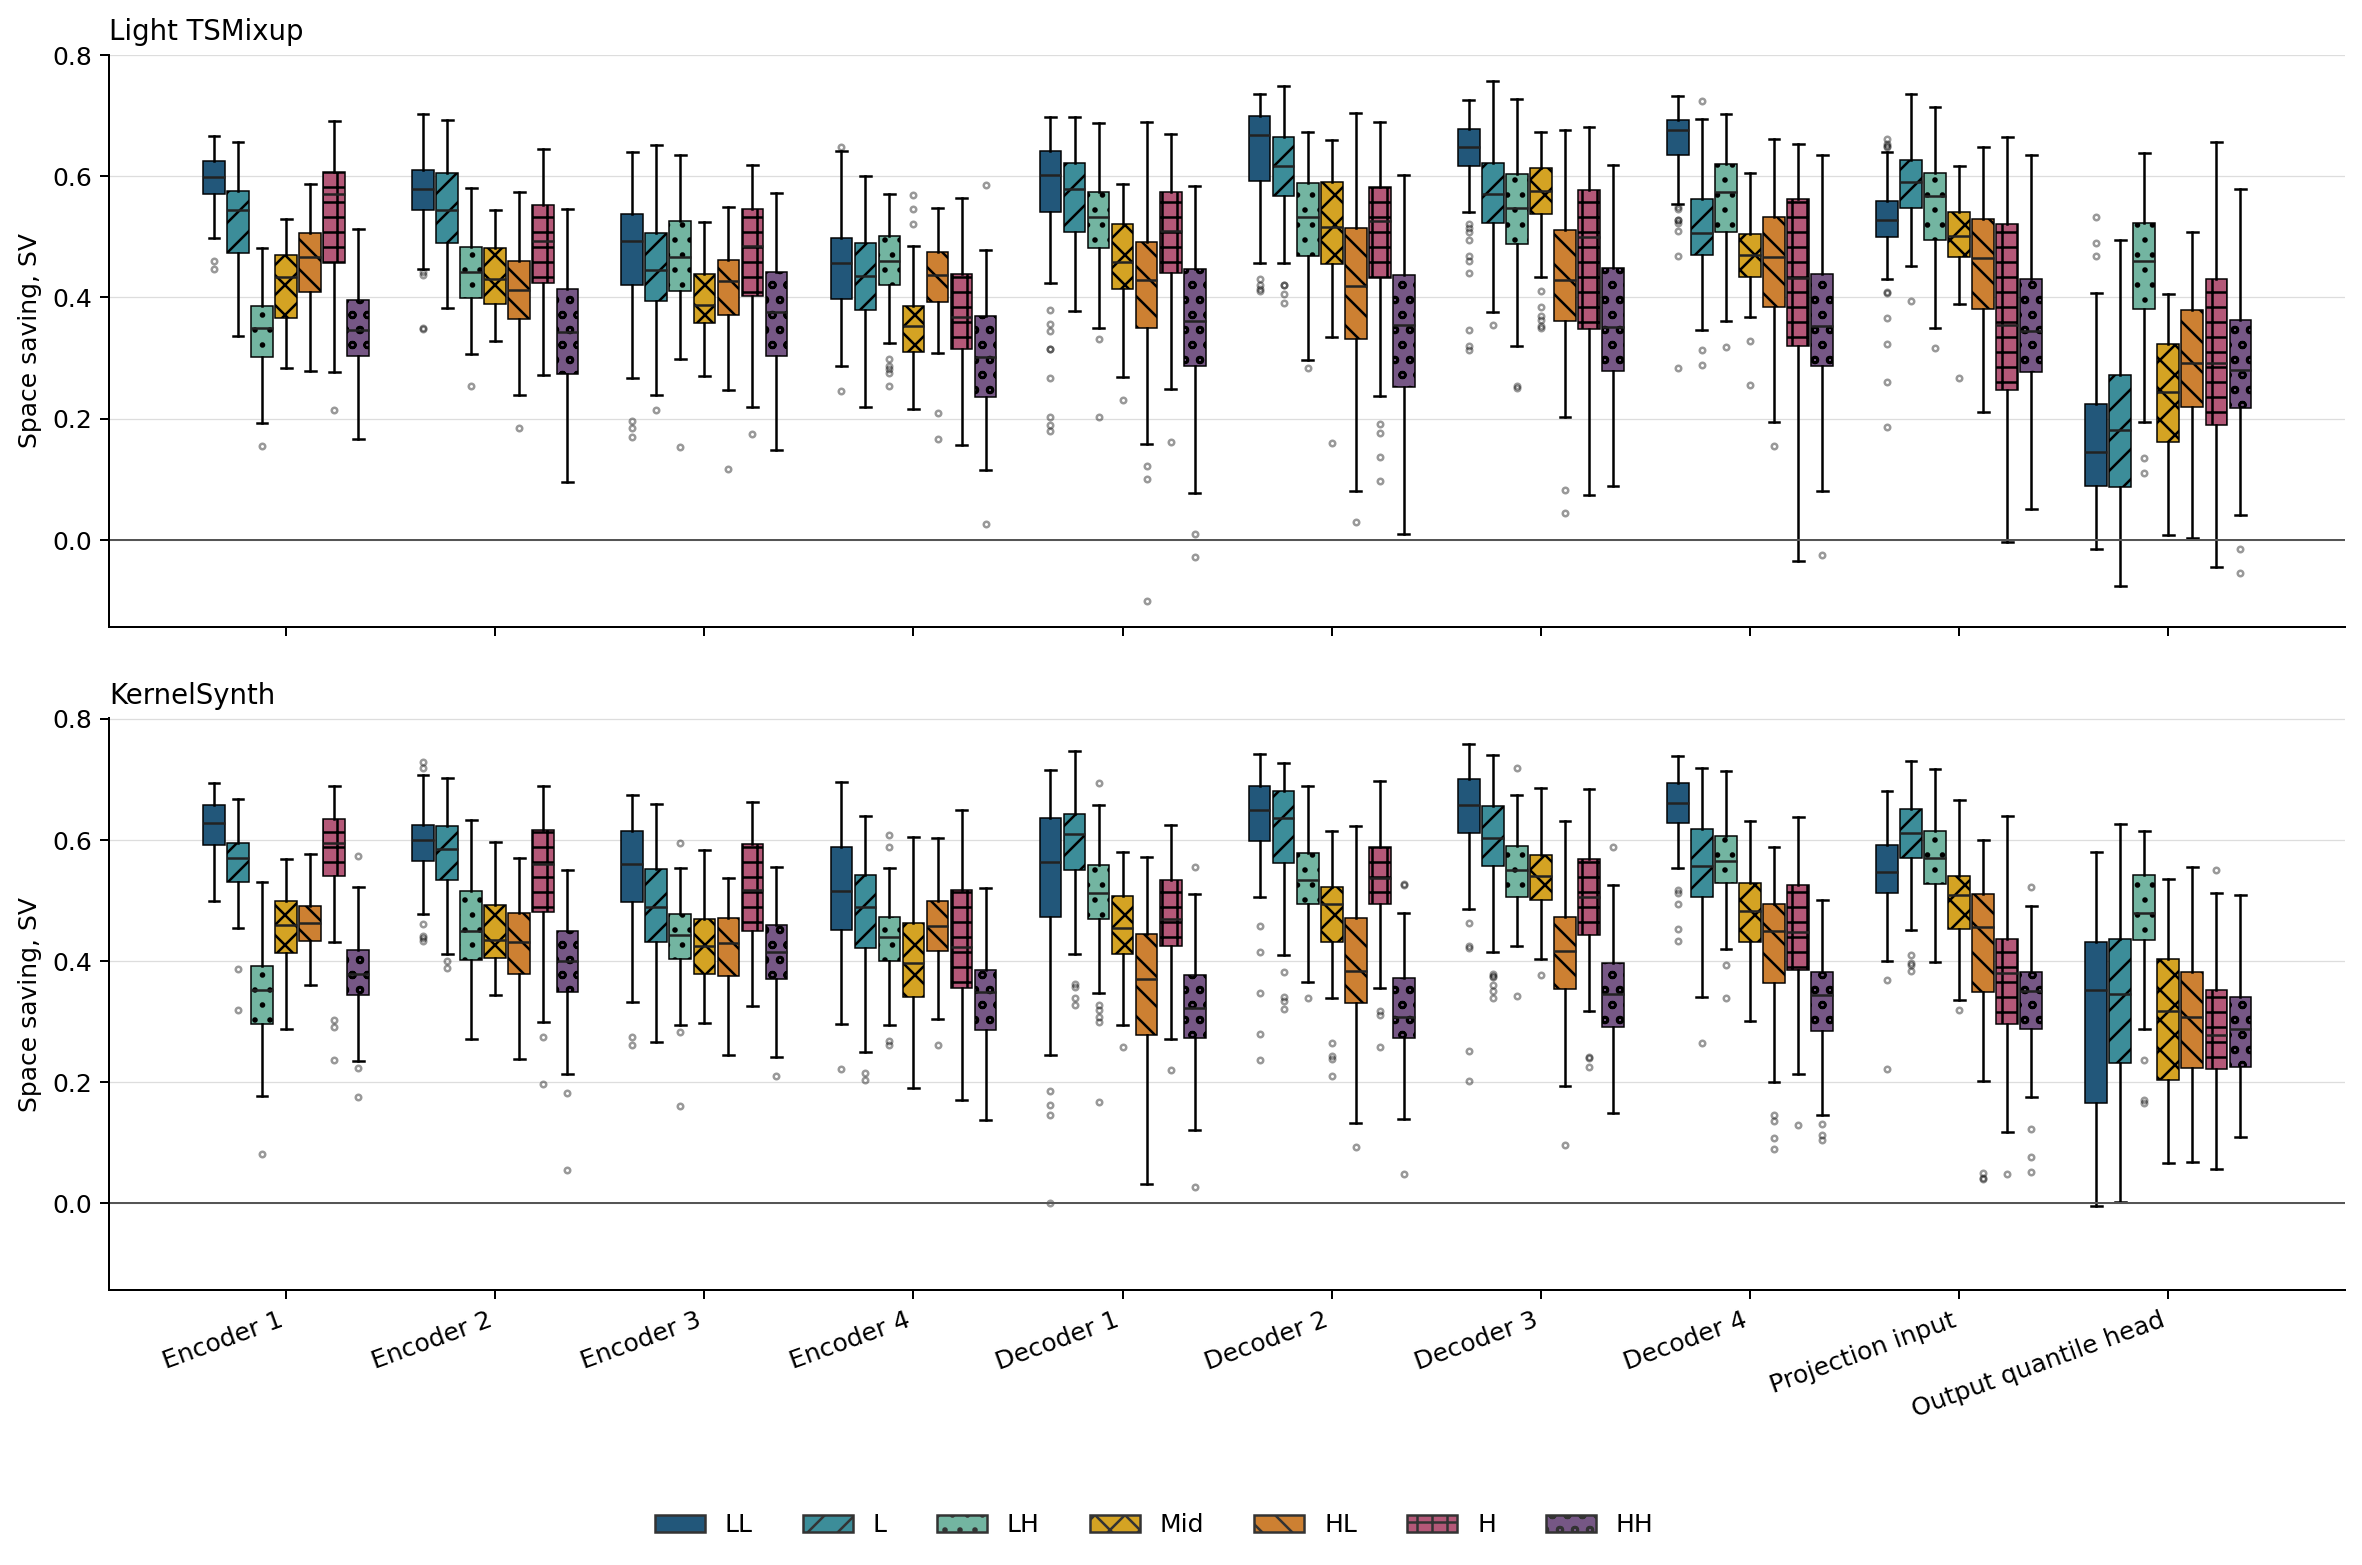

In [6]:
figure_paths = sorted(run_dir.glob(f"{prefix}sv_distribution_p16_s16.png"))
if len(figure_paths) != 1:
    raise RuntimeError(f"Expected one reference distribution figure, found {len(figure_paths)}.")
display(Image(filename=str(figure_paths[0]), width=1100))

### Lock/control reading

For each generator, a cell is the percentage of contexts in which the added
tone is located when it sits on a candidate site / when it sits beside it,
over the backgrounds of the design. The second table of each pair is the
difference in percentage points, and the third repeats it away from the task
boundaries. Read them beside Table 5 of the report: there the forecast returns
a tone more often on a site than beside it; here the question is whether the
internal state places the tone equally well in the two cases.

In [7]:
for family, label in (("tsmixup", "Light TSMixup"), ("kernelsynth", "KernelSynth")):
    display(Markdown(f"**{label}**"))
    display(lock_control_panel(lock_control, family).rename_axis("lock/control located, %"))
    display(net_panel(lock_control, family).rename_axis("net (lock - control), points"))
    display(net_panel(lock_control, family, suffix="_off").rename_axis("net, off-boundary pairs"))
    if lock_control["network"].eq("random_init").any():
        display(net_panel(lock_control, family, network="random_init").rename_axis("net, untrained network"))

**Light TSMixup**

stage,enc_0,enc_1,enc_2,enc_3,dec_0,dec_1,dec_2,dec_3,output_reg,output_head
"lock/control located, %",,,,,,,,,,
official-p16-s16,51/97,47/96,49/97,46/94,48/95,47/91,50/94,50/88,51/90,37/60
retrained-p8-s8,39/80,32/84,32/88,34/94,17/97,26/97,32/98,37/94,30/95,18/88
retrained-p16-s8,40/90,42/88,41/87,35/87,35/80,35/78,34/82,36/87,29/82,26/66
retrained-p16-s12,41/66,38/70,38/69,39/68,46/92,44/94,46/93,47/93,43/91,38/72
retrained-p16-s16,29/68,34/70,30/67,34/63,28/90,30/90,33/90,31/85,26/82,25/66
retrained-p24-s8,72/74,71/75,66/79,64/72,62/79,66/80,63/78,64/79,66/77,49/56
retrained-p24-s12,42/72,41/71,42/70,44/71,49/85,48/86,46/85,48/85,46/81,35/59
retrained-p24-s16,36/67,35/66,38/68,39/68,52/81,54/88,56/88,53/88,52/88,43/66
retrained-p24-s20,55/68,52/68,48/64,48/61,58/78,58/83,61/80,56/77,56/75,44/58


stage,enc_0,enc_1,enc_2,enc_3,dec_0,dec_1,dec_2,dec_3,output_reg,output_head
"net (lock - control), points",,,,,,,,,,
official-p16-s16,-45.5,-49.3,-48.0,-48.2,-46.5,-44.6,-43.5,-37.8,-39.5,-23.0
retrained-p8-s8,-40.8,-52.0,-56.8,-60.1,-79.8,-70.9,-65.8,-57.0,-64.7,-69.7
retrained-p16-s8,-49.7,-46.3,-45.8,-52.0,-44.7,-43.3,-48.6,-51.2,-52.7,-39.9
retrained-p16-s12,-25.4,-31.0,-30.7,-29.4,-46.2,-49.9,-46.9,-46.0,-48.1,-33.4
retrained-p16-s16,-38.7,-36.2,-36.9,-28.7,-61.5,-60.5,-56.6,-53.7,-55.7,-41.0
retrained-p24-s8,-2.3,-4.6,-12.7,-7.3,-17.0,-13.8,-15.7,-15.6,-10.7,-7.2
retrained-p24-s12,-29.3,-30.6,-28.1,-27.2,-35.8,-37.3,-39.1,-37.2,-34.8,-24.4
retrained-p24-s16,-31.1,-30.2,-29.0,-29.3,-28.5,-33.6,-32.4,-34.5,-36.6,-22.9
retrained-p24-s20,-12.8,-16.6,-15.6,-12.5,-20.2,-25.3,-19.7,-21.2,-19.1,-14.3


stage,enc_0,enc_1,enc_2,enc_3,dec_0,dec_1,dec_2,dec_3,output_reg,output_head
"net, off-boundary pairs",,,,,,,,,,
official-p16-s16,-36.2,-35.4,-35.0,-28.3,-34.6,-31.7,-34.6,-32.1,-33.7,-42.1
retrained-p8-s8,-16.1,-22.4,-37.0,-40.9,-62.4,-63.9,-58.8,-54.5,-52.7,-64.2
retrained-p16-s8,-33.1,-37.6,-43.4,-44.8,-32.1,-36.9,-43.8,-40.7,-47.6,-34.5
retrained-p16-s12,-30.6,-34.8,-29.7,-27.7,-49.7,-47.4,-44.2,-41.9,-48.4,-41.9
retrained-p16-s16,-50.0,-49.6,-37.9,-23.7,-45.0,-55.8,-50.4,-52.5,-50.0,-40.8
retrained-p24-s8,3.0,0.9,-11.6,-5.5,-18.4,-16.6,-19.1,-20.3,-11.1,-6.7
retrained-p24-s12,-25.5,-24.5,-24.2,-24.2,-36.9,-39.6,-38.7,-37.8,-35.6,-30.7
retrained-p24-s16,-41.0,-41.0,-38.0,-39.4,-16.6,-21.2,-17.0,-21.6,-25.8,-24.4
retrained-p24-s20,-14.8,-18.3,-16.6,-19.8,-21.9,-25.9,-22.4,-22.6,-25.7,-26.4


stage,enc_0,enc_1,enc_2,enc_3,dec_0,dec_1,dec_2,dec_3,output_reg,output_head
"net, untrained network",,,,,,,,,,
official-p16-s16,-72.1,-75.1,-75.5,-76.8,-69.3,-72.0,-73.6,-72.3,-72.2,-75.3
retrained-p8-s8,-80.5,-80.4,-79.3,-80.1,-80.8,-82.9,-80.8,-80.3,-79.9,-82.1
retrained-p16-s8,-57.1,-56.3,-52.1,-57.5,-49.1,-51.8,-51.0,-53.3,-52.7,-49.2
retrained-p16-s12,-28.9,-32.8,-30.7,-29.7,-28.1,-31.3,-36.8,-32.8,-33.0,-37.8
retrained-p16-s16,-72.1,-75.1,-75.5,-76.8,-69.3,-72.0,-73.6,-72.3,-72.2,-75.3
retrained-p24-s8,-11.6,-11.5,-6.6,-6.6,-13.0,-14.4,-9.2,-13.9,-13.5,-15.7
retrained-p24-s12,-14.4,-14.4,-16.8,-17.9,-18.8,-17.5,-17.5,-16.9,-17.5,-16.5
retrained-p24-s16,-16.3,-15.4,-20.0,-18.1,-18.5,-14.5,-15.8,-17.1,-16.2,-18.1
retrained-p24-s20,-12.5,-9.5,-10.8,-12.3,-9.3,-7.6,-7.7,-11.2,-11.2,-11.6


**KernelSynth**

stage,enc_0,enc_1,enc_2,enc_3,dec_0,dec_1,dec_2,dec_3,output_reg,output_head
"lock/control located, %",,,,,,,,,,
official-p16-s16,53/98,52/99,50/99,45/98,48/98,48/96,51/95,55/94,55/95,42/71
retrained-p8-s8,41/80,37/87,31/93,30/94,16/95,24/95,34/96,36/92,29/94,19/88
retrained-p16-s8,39/88,38/87,38/84,34/82,35/75,33/78,32/80,31/84,29/84,24/76
retrained-p16-s12,41/73,35/74,34/75,36/74,40/87,42/89,44/89,41/90,40/88,37/77
retrained-p16-s16,28/72,34/76,32/72,31/68,28/89,33/87,33/89,32/85,27/86,30/72
retrained-p24-s8,69/78,65/76,67/76,62/74,56/81,58/81,54/80,54/79,56/79,46/65
retrained-p24-s12,41/69,42/71,41/73,42/74,44/82,46/85,45/85,44/85,42/82,36/65
retrained-p24-s16,38/70,39/73,43/76,43/75,50/84,57/88,53/87,53/86,49/84,44/71
retrained-p24-s20,54/70,53/71,47/63,48/60,56/77,58/77,60/76,56/76,56/76,46/60


stage,enc_0,enc_1,enc_2,enc_3,dec_0,dec_1,dec_2,dec_3,output_reg,output_head
"net (lock - control), points",,,,,,,,,,
official-p16-s16,-45.2,-47.6,-49.0,-53.5,-49.5,-47.2,-44.3,-38.8,-39.8,-29.4
retrained-p8-s8,-39.3,-50.1,-61.7,-63.9,-79.8,-71.4,-61.7,-56.2,-64.5,-68.5
retrained-p16-s8,-49.1,-49.3,-46.8,-48.1,-40.1,-44.9,-48.4,-52.6,-54.6,-52.2
retrained-p16-s12,-31.4,-38.3,-41.4,-38.0,-46.1,-47.5,-45.0,-49.2,-48.5,-39.9
retrained-p16-s16,-44.2,-42.0,-39.0,-37.0,-60.6,-53.8,-55.9,-53.5,-58.7,-42.1
retrained-p24-s8,-8.4,-11.0,-9.1,-12.2,-25.6,-23.8,-25.6,-24.9,-23.2,-19.5
retrained-p24-s12,-28.2,-29.3,-31.4,-31.1,-38.1,-39.1,-39.7,-41.3,-40.3,-29.6
retrained-p24-s16,-32.5,-34.4,-32.5,-32.2,-34.1,-31.4,-33.4,-33.1,-35.0,-27.4
retrained-p24-s20,-16.6,-18.2,-15.3,-12.2,-20.7,-19.6,-16.3,-20.7,-19.2,-14.5


stage,enc_0,enc_1,enc_2,enc_3,dec_0,dec_1,dec_2,dec_3,output_reg,output_head
"net, off-boundary pairs",,,,,,,,,,
official-p16-s16,-37.5,-34.6,-37.9,-31.7,-37.1,-33.8,-29.2,-32.1,-31.2,-40.4
retrained-p8-s8,-17.9,-34.5,-55.2,-49.1,-70.3,-63.0,-58.2,-57.3,-55.5,-61.8
retrained-p16-s8,-30.7,-32.4,-28.3,-29.3,-23.4,-33.4,-36.9,-40.0,-46.6,-39.3
retrained-p16-s12,-35.2,-43.2,-45.5,-40.3,-49.7,-48.4,-49.7,-52.9,-54.2,-53.9
retrained-p16-s16,-59.2,-55.8,-51.2,-34.6,-45.0,-40.8,-46.7,-45.4,-45.8,-44.6
retrained-p24-s8,-3.4,-5.9,-4.5,-9.4,-25.9,-25.5,-29.2,-27.3,-22.7,-20.8
retrained-p24-s12,-24.0,-25.1,-26.9,-25.5,-37.8,-36.9,-34.0,-39.8,-37.3,-32.7
retrained-p24-s16,-40.4,-40.0,-36.0,-35.0,-24.8,-19.6,-22.8,-18.2,-24.0,-22.6
retrained-p24-s20,-19.0,-22.6,-23.6,-21.7,-21.9,-20.7,-18.3,-23.6,-24.0,-23.6


stage,enc_0,enc_1,enc_2,enc_3,dec_0,dec_1,dec_2,dec_3,output_reg,output_head
"net, untrained network",,,,,,,,,,
official-p16-s16,-68.8,-72.3,-73.1,-72.5,-66.7,-70.7,-71.3,-71.6,-71.6,-71.7
retrained-p8-s8,-81.5,-81.5,-81.4,-79.2,-82.2,-83.9,-82.9,-83.5,-83.2,-83.4
retrained-p16-s8,-58.9,-59.1,-55.6,-59.3,-51.5,-53.2,-51.2,-54.4,-54.2,-51.9
retrained-p16-s12,-31.6,-38.3,-36.0,-35.4,-31.3,-36.3,-39.3,-36.8,-36.9,-40.0
retrained-p16-s16,-68.8,-72.3,-73.1,-72.5,-66.7,-70.7,-71.3,-71.6,-71.6,-71.7
retrained-p24-s8,-7.3,-7.5,-5.3,-6.7,-10.9,-10.8,-9.0,-12.9,-12.4,-14.5
retrained-p24-s12,-17.0,-17.4,-18.8,-17.7,-18.2,-16.5,-19.3,-18.7,-18.6,-20.4
retrained-p24-s16,-14.4,-15.9,-15.9,-15.7,-16.4,-12.1,-13.8,-15.5,-15.7,-15.6
retrained-p24-s20,-2.4,-4.8,-3.0,-4.4,-0.9,3.9,4.5,2.8,2.7,1.1


### Export inventory

In [8]:
exported = sorted(path for path in run_dir.rglob("*") if path.is_file() and path.suffix in {".png", ".pdf", ".tex", ".txt"})
print(f"{len(exported)} table/figure/caption export files; raw outcomes and distribution summaries are saved as CSV.")
display(pd.DataFrame({"export": [str(path.relative_to(run_dir)) for path in exported]}).head(24))
copied = publish([path for path in run_dir.iterdir() if path.is_file() and path.suffix in {".tex", ".pdf", ".txt"}]
                 + [run_dir / name for name in ("sv_distribution.csv", "compression_counts.csv", "complex_lock_control.csv")
                    if (run_dir / name).is_file()])
print(f"{len(copied)} files copied to {PUBLISHED}" if copied else "Smoke mode: nothing copied to the tracked folder.")

5 table/figure/caption export files; raw outcomes and distribution summaries are saved as CSV.
7 files copied to notebooks/signal_analysis/results/probing


,export
0,probing_compression.tex
1,probing_compression_caption.txt
2,probing_lock_control_backgrounds.tex
3,sv_distribution_p16_s16.pdf
4,sv_distribution_p16_s16.png


## Takeaways

Read the medians together with their quartiles and the two controls, and the
lock/control differences next to the recovery count. A readable band at the
output head does not by itself establish recovery in the forecast, and a
difference at a site whose pairs lie beside a task boundary is not evidence of
a site effect. The solar series is not used in this experiment.

In [9]:
if MODE == "smoke":
    display(Markdown("**Smoke validation only:** the reduced-background values cannot be used as the report's 100-background tables."))
else:
    if cfg.n_backgrounds != 100 or not counts["n"].eq(100).all():
        raise ValueError("The report tables require 100 valid outcomes in every cell.")
    display(Markdown("Every displayed full-design value rests on 100 valid background outcomes. The LaTeX/CSV exports are ready for Section 5.2 and Appendix G."))

Every displayed full-design value rests on 100 valid background outcomes. The LaTeX/CSV exports are ready for Section 5.2 and Appendix G.